#### simple multiagent 

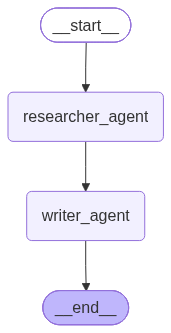

In [2]:
from langgraph.graph import StateGraph,START,END,MessagesState
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.types import interrupt, Command
from langchain_tavily import TavilySearch
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command


In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

In [4]:
os.environ['GROQ_API_KEY'] is None

False

In [5]:
os.environ['GROQ_API_KEY'][:5]

'gsk_N'

In [6]:
# state is there to store the current information about the data and can update the thingd when needed
class AgentState(MessagesState):
    next_agent :str  # will decide which agent should go next

#message state is used to maanage oconverstaion messages


In [7]:
from langchain_community.tools.tavily_search import TavilySearchResults
#custome tool

@tool
def search_query(query:str):
    """this tool is responsible for searching the answer on the web"""
    tavily = TavilySearchResults(max_results=3) #returns the list of results while tavily search will return the result in dictionary
    res=tavily.invoke({"query": query})
    return str(res)

@tool
def write_summary(content:str):
    """write a summary of the provided content"""
    summary=f"summary of findings:\n\n{content[:500]}"
    return summary

C:\Users\Azrap\AppData\Local\Temp\ipykernel_20016\28635371.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [8]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="openai/gpt-oss-120b")

In [9]:
from langchain.messages import SystemMessage

#create researcher agent
def researcher_agent(state:AgentState):
    """researcher agent to do research """
    messages=state['messages']

    #add system msg
    system_msg=SystemMessage(content="you are a researcher , a research assistant whose aim is to do the research onn topics given use the search_query tool to do the research...")

    researcher_llm=llm.bind_tools([search_query])
    response=researcher_llm.invoke([system_msg]+messages)

    return {
        "messages":[response],
        "next_agent":"writer"
    }

In [10]:
# writter agent
def writer_agent(state:AgentState):
    """writer agent for writing the content based on info provided"""

    message=state['messages']

    system_msg=SystemMessage(content="you are a writer who is reposnible for writing basd on the content provided")

    writer_llm = llm.bind_tools([write_summary, search_query])
    response=writer_llm.invoke([system_msg]+message)

    return {
        "messages":[response],
        "next_agent":"END"
    }

```
see the format of messges 
state = {
    "messages": [
        HumanMessage(content="Search about Agentic AI"),
        AIMessage(
            content="",
            tool_calls=[
                {
                    "name": "search_query",
                    "args": {"query": "Agentic AI"},
                    "id": "call_123",
                    "type": "tool_call"
                }
            ]
        )
    ]
}
so inside a messages the last message means if we do messages[-1] this will taklek the ai messgase that is AIMessage(
            content="",
            tool_calls=[
                {
                    "name": "search_query",
                    "args": {"query": "Agentic AI"},
                    "id": "call_123",
                    "type": "tool_call"
                }
            ]
        )
        this is because we want o se weather ai made a tool call request 
```

In [11]:
# tool executer node

def execute_tools(state:AgentState):

    messages=state['messages']
    last_message=messages[-1]

    if hasattr(last_message,"tool_calls") and last_message.tool_calls: # this hasattr will check wither the last messages has tool_calls attribute in it or not...last_message.tool_calls — check karta hai ki us attribute mein koi tool call hai ya nahi.
        tool_node=ToolNode([search_query,write_summary])

        response=tool_node.invoke(state)
        return response
    
    return state

In [14]:
graph=StateGraph(MessagesState)

graph.add_node("researcher_agent",researcher_agent)
graph.add_node("writer_agent",writer_agent)

graph.add_edge(START,"researcher_agent")
graph.add_edge("researcher_agent","writer_agent")
graph.add_edge("writer_agent",END)

graph=graph.compile()



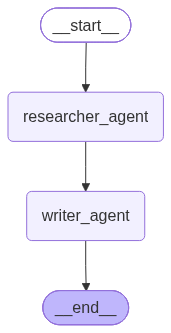

In [17]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [18]:
graph.invoke({"messages":"research about agentic ai in buisness"})

{'messages': [HumanMessage(content='research about agentic ai in buisness', additional_kwargs={}, response_metadata={}, id='286781d6-fb2a-4f91-a641-ad91f8d8f784'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants research about "agentic AI in business". We need to use search_query tool to gather info. Probably multiple queries. We\'ll search web.', 'tool_calls': [{'id': 'fc_9e00bea9-7e74-4b36-b57e-4e33f016de71', 'function': {'arguments': '{"query":"agentic AI in business applications"}', 'name': 'search_query'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 64, 'prompt_tokens': 165, 'total_tokens': 229, 'completion_time': 0.135394131, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.007027925, 'prompt_tokens_details': None, 'queue_time': 0.34180401, 'total_time': 0.142422056}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'to

In [25]:
graph=StateGraph(MessagesState)
graph = StateGraph(AgentState)

# First, register all nodes
graph.add_node("researcher_agent", researcher_agent)
graph.add_node("writer_agent", writer_agent)
graph.add_node(
    "execute_tools",
    ToolNode([search_query, write_summary])
)

# Then, connect the nodes
graph.add_edge(START, "researcher_agent")

graph.add_conditional_edges(
    "researcher_agent",
    tools_condition,
    {
        "tools": "execute_tools",
        END: "writer_agent"
    }
)

graph.add_edge("execute_tools", "researcher_agent")
graph.add_edge("writer_agent", END)

# Compile after adding all nodes and edges
app = graph.compile()

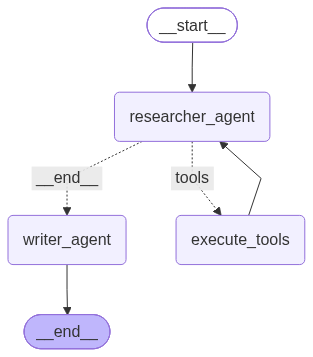

In [26]:
app

In [32]:
result = app.invoke({
    "messages": [
        ("human", """
        Here is my LangGraph code:

        from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

graph = StateGraph(AgentState)

# First, register all nodes
graph.add_node("researcher_agent", researcher_agent)
graph.add_node("writer_agent", writer_agent)
graph.add_node(
    "execute_tools",
    ToolNode([search_query, write_summary])
)

# Then, connect the nodes
graph.add_edge(START, "researcher_agent")

graph.add_conditional_edges(
    "researcher_agent",
    tools_condition,
    {
        "tools": "execute_tools",
        END: "writer_agent"
    }
)

graph.add_edge("execute_tools", "researcher_agent")
graph.add_edge("writer_agent", END)

# Compile after adding all nodes and edges
app = graph.compile()

        Explain my code line by line in very simple language.
        Explain only one step at a time.
        Don't rewrite my code or add unnecessary things.
    
        """)
    ]
})

In [33]:
print(result["messages"][-1].content)

**Step 1**  
`from langgraph.graph import StateGraph, START, END` – We import the `StateGraph` class (used to build a graph of agents) and the special markers `START` and `END` that denote the beginning and the end of the workflow.

---

**Step 2**  
`from langgraph.prebuilt import ToolNode, tools_condition` – We bring in two ready‑made helpers: `ToolNode`, which lets a node run external tools, and `tools_condition`, a function that decides whether the next step should be a tool call or move on.

---

**Step 3**  
`graph = StateGraph(AgentState)` – We create a new graph object called `graph`. It will manage the flow of our agents, and we tell it that the state it will pass around is described by `AgentState` (a data structure you defined elsewhere).

---

**Step 4**  
`graph.add_node("researcher_agent", researcher_agent)` – We add a node named `"researcher_agent"` to the graph and link it to the actual function (or agent) called `researcher_agent`. When the graph reaches this node, tha